# MSCS 634 — Deliverable 1
**Team:** Team supernova  
**Dataset:** Wisconsin Diagnostic Breast Cancer

In [1]:
# Import the tools used to load, inspect, clean, and visualize the dataset.
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score, mean_squared_error, accuracy_score, f1_score, roc_auc_score, silhouette_score, ConfusionMatrixDisplay, RocCurveDisplay
# Use a consistent plotting style and load the CSV from this deliverable folder.
sns.set_theme(style='whitegrid')
df = pd.read_csv('data/breast_cancer.csv')
print('Dataset shape:',df.shape)


Dataset shape: (569, 31)


## Dataset selection
The Wisconsin Diagnostic Breast Cancer (WDBC) dataset contains 569 observations and 30 numeric predictors, plus a binary diagnosis target. Each row describes measurements computed from a digitized fine-needle aspirate (FNA) image of a breast mass. Ten nucleus characteristics (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, and fractal dimension) are represented by mean, standard error, and worst values. In this dataset, “worst” is the mean of the three largest values, not a single maximum. The target encoding is 0 = malignant and 1 = benign.

This dataset meets the project's minimum size and attribute requirements and supports binary classification and exploratory unsupervised analysis. Regression is less direct: predicting a measurement would not be the same as predicting a clinical outcome. Association-rule mining will require documented discretization of numeric features. Source: [UCI Machine Learning Repository — Breast Cancer Wisconsin (Diagnostic)](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic); also available through scikit-learn. This data is for coursework, not clinical use.

## Inspect and clean

The checks below establish the input shape and types, summarize numeric ranges, and test for missing values, exact duplicate rows, and unexpected diagnosis labels. No imputation or row removal is needed for the current CSV. The median-imputation fallback and duplicate removal are retained to make the cleaning steps explicit if the input changes. Potential outliers are flagged with the 1.5×IQR rule but not automatically removed: an unusual measurement is not necessarily a data error.

In [2]:
# Review example rows, column types, and numeric ranges before changing any values.
display(df.head());df.info();display(df.describe().T)
# Count missing cells and exact duplicate rows so cleaning decisions are evidence-based.
print('Missing values:',int(df.isna().sum().sum()),'Duplicate rows:',int(df.duplicated().sum()))
# Confirm that the diagnosis label has only the documented binary values.
assert set(df.target.unique()) == {0,1}
# Remove exact duplicate records; preserve all distinct observations.
clean=df.drop_duplicates().copy()
# If a future input has missing numeric data, fill it with each column's median.
if clean.isna().any().any():clean=clean.fillna(clean.median(numeric_only=True))
# Flag unusually distant predictor values for review; do not assume they are errors.
flag_counts={}
for col in clean.drop(columns='target'):
 q1,q3=clean[col].quantile([.25,.75]);iqr=q3-q1
 flag_counts[col]=int(((clean[col]<q1-1.5*iqr)|(clean[col]>q3+1.5*iqr)).sum())
print('Most IQR-flagged:',sorted(flag_counts.items(),key=lambda x:-x[1])[:8])
# Save the cleaned dataset so later project deliverables can reuse the same data.
clean.to_csv('data/cleaned_breast_cancer.csv',index=False)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


Missing values: 0 Duplicate rows: 0
Most IQR-flagged: [('area error', 65), ('radius error', 38), ('perimeter error', 38), ('worst area', 35), ('smoothness error', 30), ('compactness error', 28), ('fractal dimension error', 28), ('symmetry error', 27)]


## EDA and feature relationships

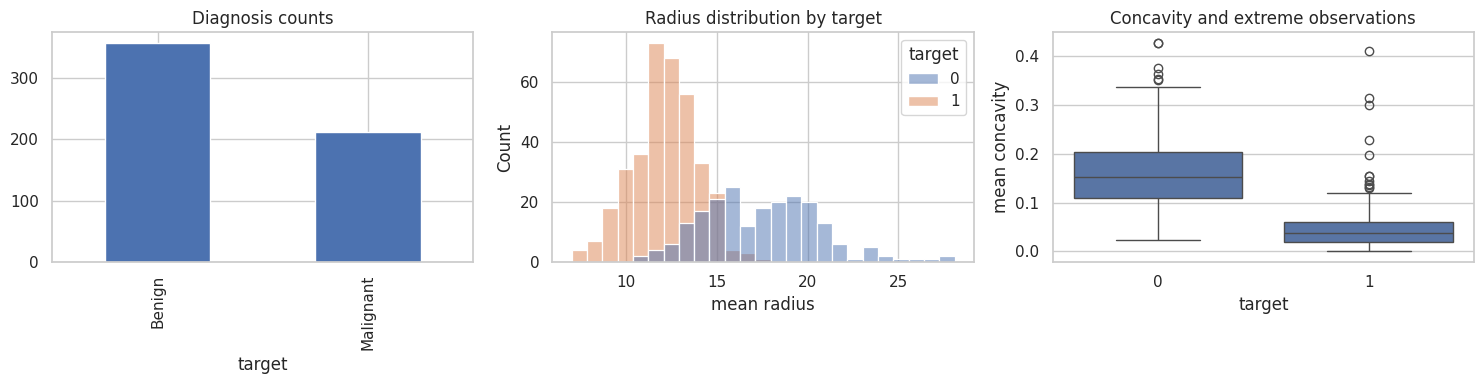

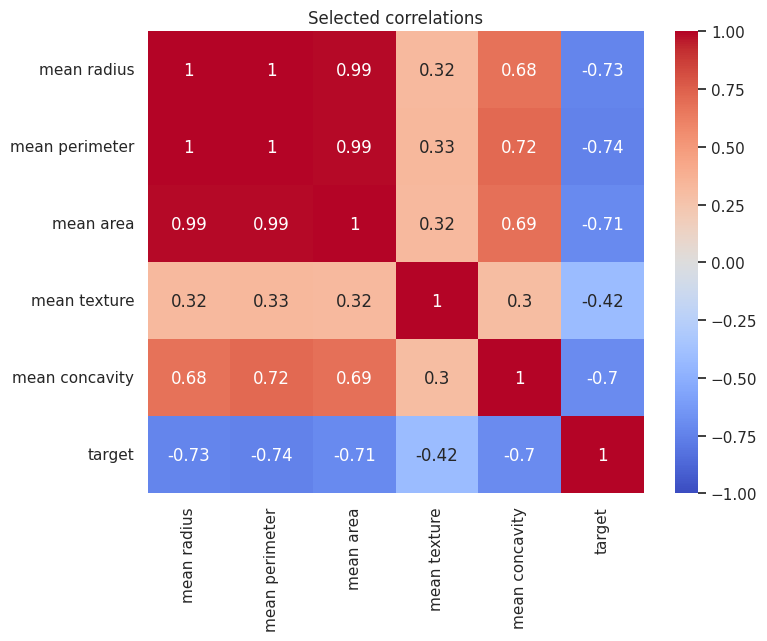

Class counts: {1: 357, 0: 212}
Radius-perimeter correlation: 0.9979


In [3]:
# Compare class frequency, a size measurement, and a shape measurement by diagnosis.
fig,ax=plt.subplots(1,3,figsize=(15,4))
clean.target.map({0:'Malignant',1:'Benign'}).value_counts().plot.bar(ax=ax[0],title='Diagnosis counts')
sns.histplot(data=clean,x='mean radius',hue='target',bins=25,ax=ax[1]);ax[1].set_title('Radius distribution by target')
sns.boxplot(data=clean,x='target',y='mean concavity',ax=ax[2]);ax[2].set_title('Concavity and extreme observations')
plt.tight_layout();plt.show()
# Inspect relationships among a small set of measurements and the binary target.
selected=['mean radius','mean perimeter','mean area','mean texture','mean concavity','target']
plt.figure(figsize=(8,6));sns.heatmap(clean[selected].corr(),annot=True,cmap='coolwarm',vmin=-1,vmax=1);plt.title('Selected correlations');plt.show()
print('Class counts:',clean.target.value_counts().to_dict())
print('Radius-perimeter correlation:',round(clean['mean radius'].corr(clean['mean perimeter']),4))


## Interpretation
### Findings and modeling implications

- **Class distribution:** There are 357 benign and 212 malignant cases (about 62.7% and 37.3%). This moderate imbalance means accuracy alone could hide weak malignant-case detection. Use stratified splits and report malignant recall, precision, F1, and a confusion matrix in the classification deliverable.
- **Radius distribution:** The plot compares mean-radius distributions by diagnosis. Differences can motivate using the feature in a baseline classifier, but any overlap means radius alone is not a sufficient decision rule. Compare multivariate models and avoid making causal or clinical claims from this visualization.
- **Concavity and extremes:** The boxplot highlights variation and possible extremes in mean concavity. The IQR procedure flags observations for review, not automatic deletion. Check whether flagged observations are plausible and compare model sensitivity only if there is a justified alternative cleaning choice.
- **Correlated size measures:** Mean radius and mean perimeter have correlation 0.9979; the selected heatmap also helps inspect area and other relationships. These measures carry overlapping size information, which can destabilize unregularized regression coefficients and give redundant features extra influence in distance-based methods. Later work should compare standardized, regularized, or reduced-feature models and fit preprocessing only on training data.
- **Scope:** The dataset is small and historical, and contains no demographic variables for subgroup fairness analysis. Findings are useful for coursework exploration, not for estimating current clinical effectiveness or making patient-level decisions.

### Challenges to carry forward

The strongest practical challenges are correlated predictors, different measurement scales, a moderately uneven target distribution, and uncertainty about whether IQR-flagged values are genuine. The sample size also limits how confidently performance can be generalized. For later modeling, use pipelines to prevent scaling leakage, stratify evaluation, inspect class-sensitive metrics, and report sensitivity to any defensible feature-selection or outlier-handling choice. Regression and association rules need extra care: define a meaningful numeric response for regression, and document feature discretization while avoiding rules that merely restate the diagnosis label.